Jain's Fairness Index - A measurement of equality in allocation or achieved fairness between clients.
Cite: A Fairness Perspective on Client Selection and Aggregation Methods for Non-IID Mitigation in Federated Learning: A Survey


Author: Heather Lemon


Date: 24/11/2026

## CFAIR-10

In [133]:
import torch
import torchvision
from torchvision.transforms import v2
import torch.nn as nn
import torch.nn.functional as nnFunctional
import torch.optim as optim

import matplotlib.pyplot as plt
import numpy as np


device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')
print(device, ' device detected')

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

# split test & train
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

class CIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super(CIFAR10CNN, self).__init__()
        # 2 CNN models with 2 5x5 layers, each with 64 channels
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=5)
        # 2x2 max pool
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 5 * 5, 384)
        self.fc2 = nn.Linear(384, 192)
        self.fc3 = nn.Linear(192, num_classes)

    def forward(self, x):
        # flatten images except batch
        x = self.pool(nnFunctional.relu(self.conv1(x)))
        x = self.pool(nnFunctional.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = nnFunctional.relu(self.fc1(x))
        x = nnFunctional.relu(self.fc2(x))
        return self.fc3(x)

if __name__ == "__main__":
    print("\nTesting CIFAR-10 Model...")
    c_model = CIFAR10CNN()
    c_model.to(device=device)
    # Simulate 1 RGB 32x32 image
    c_input = torch.randn(1, 3, 32, 32)
    c_output = c_model(c_input.to(device))
    print(f"CIFAR-10 Output Shape: {c_output.shape} (Expected: [1, 10])")


cuda  device detected

Testing CIFAR-10 Model...
CIFAR-10 Output Shape: torch.Size([1, 10]) (Expected: [1, 10])


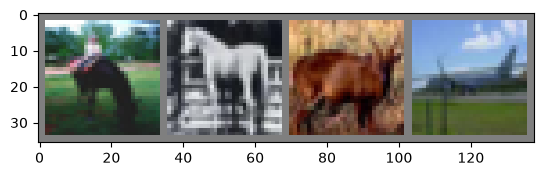

horse horse deer  plane


In [134]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    # np.transpose(a=npimg, axes=(0,1,2))
    plt.imshow(np.transpose(a=npimg, axes=(1,2,0)))
    plt.show()

dataiter = iter(trainloader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

### Loss function and optimizer

In [135]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(CIFAR10CNN.parameters(c_model), lr=0.001, momentum=0.9)

In [136]:
for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data[0].to(device), data[1].to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = c_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

print('Finished Training')

SAVED_MODEL = './cifar_net.pt'
torch.save(c_model.state_dict(), SAVED_MODEL)
print("saved cifar_net.pt")

[1,  2000] loss: 2.063
[1,  4000] loss: 1.667
[1,  6000] loss: 1.508
[1,  8000] loss: 1.422
[1, 10000] loss: 1.354
[1, 12000] loss: 1.273
[2,  2000] loss: 1.175
[2,  4000] loss: 1.115
[2,  6000] loss: 1.097
[2,  8000] loss: 1.034
[2, 10000] loss: 0.997
[2, 12000] loss: 0.978
Finished Training
saved cifar_net.pt


#### Display Image from Test set

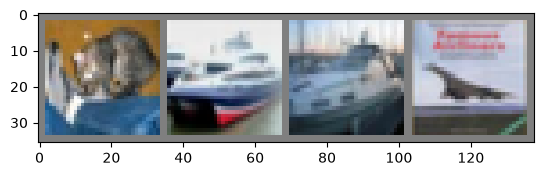

GroundTruth:  cat   ship  ship  plane


In [137]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

In [138]:
csmodel = CIFAR10CNN()
csmodel.load_state_dict(torch.load(SAVED_MODEL, weights_only=True))

<All keys matched successfully>

In [139]:
outputs = csmodel(images)

In [140]:
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ''.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

Predicted:  cat  ship ship plane


In [141]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = csmodel(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 67 %


In [144]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = csmodel(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 72.5 %
Accuracy for class: car   is 71.2 %
Accuracy for class: bird  is 65.1 %
Accuracy for class: cat   is 46.1 %
Accuracy for class: deer  is 60.9 %
Accuracy for class: dog   is 50.1 %
Accuracy for class: frog  is 63.3 %
Accuracy for class: horse is 77.0 %
Accuracy for class: ship  is 79.0 %
Accuracy for class: truck is 85.3 %
